In [2]:

### imports
# basics
import numpy as np
import matplotlib.pyplot as plt
import warnings
import xarray as xr

# jax (automatic differentiation, used to check our own gradients)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, as in numpy

# ### our own functions, sorted by topic (the .py files in the same folder as this notebook)
# # activation functions and their derivatives
# from activations import (ReLU, ReLU_der, leaky_ReLU, leaky_ReLU_der, sigmoid, sigmoid_der,
#                          identity, identity_der, softmax)
# # cost functions, derivatives and error metrics
# #from costs import (mse, mse_der, MSE, R2, mse_der_batch, output_error_softmax_ce, cross_entropy, accuracy)

# # the feed-forward network: layers, feed forward, backpropagation, set-up
# from feedforward import (create_layers, feed_forward, cost, feed_forward_saver, backpropagation,
#                          create_layers_batch, feed_forward_batch, feed_forward_saver_batch, cost_batch,
#                          backpropagation_batch, init_layers, predict, setup_NN)

# # training loop and CV of the regression network (part b/c)
# from training import train, cv_mse_nopen
# # OLS / Ridge / Lasso benchmarks from project 1
# from ols_regression import cost_ols, closed_form, gradient, OLS_regression, fit_poly, poly_cv
# # plot helpers
# from plotting import heatmap_nopen
# # part d): L1 / L2 penalties
# from task_d import (penalty_grad, backprop_penalised, train_penalised, build_net, penalised_cost_jax,
#                     check_gradient_jax, cv_mse, lam_label)

from reading_noresm import read_noresm_cmor, Modelinfo, global_avg
import functions_heatbudget as fhb

### random seed for reproducibility
rng = np.random.default_rng(2026)

### defining colors and fontsize for plotting
BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
train_color = "#32A911"
test_color = "#048582"

label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


### Reading the data

In [3]:
# Functions that need to be moved to a separate .py script

def read_data(period="historical"):
    """    INPUT    """
    modelname = "NorESM2-MM"  # name of model
    realiz = "r1i1p1f1"  # ensemble member
    """ END OF INPUT """

    if period == "historical":
        #Information of experiments in each period
        exps = "historical"
        activity_id = "CMIP"
    elif period == "ssp585":
        #Information of experiments in each period
        exps = "ssp585"
        activity_id = "ScenarioMIP"
    elif period == "sample":
        #Information of experiments in each period
        exps = "historical"
        activity_id = "CMIP"
    else:
        raise ValueError("Period must be either 'historical', 'ssp585', or 'sample'.")

    model = Modelinfo(name=modelname, activity_id=activity_id, expid=exps, realiz=realiz)

    #Reading the different experiments and getting the 30 year periods
    if period == "historical":
        var = fhb.read_atmos_data(model=model,first_year = 1985,last_year = 2014)
        base = fhb.read_atmos_data(model=model,first_year = 1850,last_year = 1879)
    elif period == "ssp585":
        var = fhb.read_atmos_data(model=model,first_year = 2071,last_year = 2100)
        model_base = Modelinfo(name=modelname, activity_id="CMIP", expid="historical", realiz=realiz)
        base = fhb.read_atmos_data(model=model_base,first_year = 1985,last_year = 2014)
    elif period == "sample":
        var = xr.open_dataset("ds_sample.nc") #sample data that exists in the folder, to run without access to all NorESM data
        base = xr.open_dataset("base_sample.nc")

    return var, base



### Calculating the SEB contributions analytically

test 1


/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


test2 


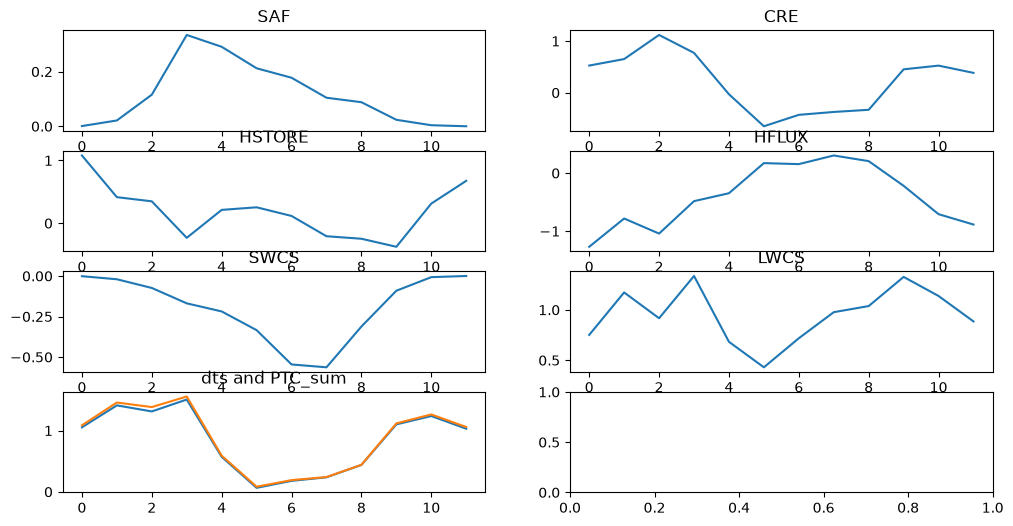

In [17]:

period = "historical"
ds, base = read_data(period=period)

#base_mean = base.mean(dim="time")
# ptc_temp = fhb.partial_temperature_fluxes(ds, base_mean).sel(lat=slice(66, None)).load()



# ds_fut, base_fut = read_data(period="ssp585")

base_mean = base.groupby('time.month').mean() 
ds_mean = ds.groupby('time.month').mean() 
month = np.arange(1,13)

print("test 1")
ptc_temp = fhb.partial_temperature_contributions(ds_mean,base_mean).sel(lat=slice(66,None)).load()

print("test2 ")


areacella = xr.open_dataset("/projects/NS9034K/CMIP6/CMIP/NCC/NorESM2-MM/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_NorESM2-MM_piControl_r1i1p1f1_gn.nc")
area = areacella.areacella.sel(lat=slice(66,None))/areacella.areacella.sel(lat=slice(66,None)).sum(dim=("lat","lon"))

#Selecting the Arctic region
ptc_subset = ptc_temp#.sel(month=[1,2,10,11,12])
ptc_ave = (ptc_subset*area).sum(dim=("lat","lon"))


fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_ave.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_ave.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_ave.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_ave.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_ave.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_ave.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_ave.dts[:12].values, label="dts")
ax[3,0].plot(ptc_ave.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

test 1


/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


test2 


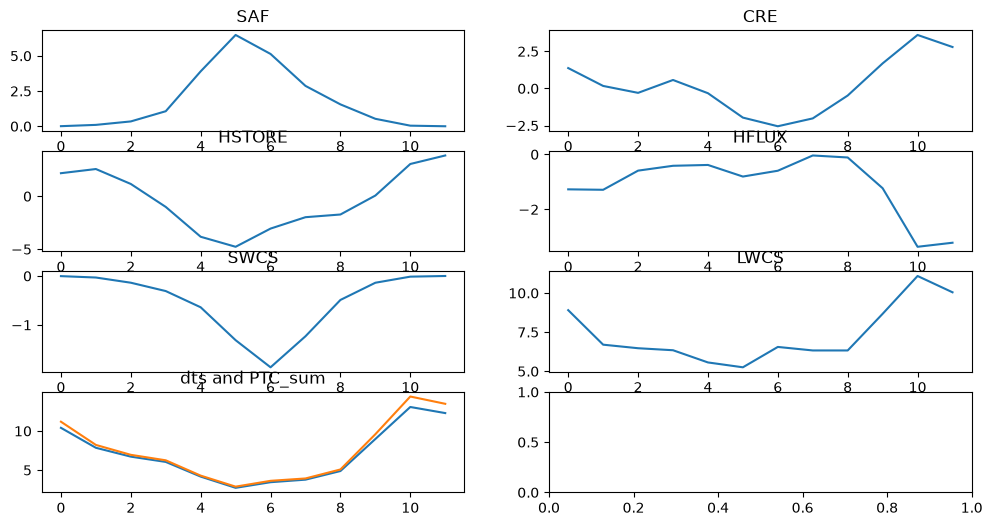

In [18]:

period = "ssp585"
ds, base = read_data(period=period)

base_mean = base.groupby('time.month').mean() 
ds_mean = ds.groupby('time.month').mean() 
month = np.arange(1,13)

print("test 1")
ptc_temp = fhb.partial_temperature_contributions(ds_mean,base_mean).sel(lat=slice(66,None)).load()

print("test2 ")


areacella = xr.open_dataset("/projects/NS9034K/CMIP6/CMIP/NCC/NorESM2-MM/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_NorESM2-MM_piControl_r1i1p1f1_gn.nc")
area = areacella.areacella.sel(lat=slice(66,None))/areacella.areacella.sel(lat=slice(66,None)).sum(dim=("lat","lon"))

#Selecting the Arctic region
ptc_subset = ptc_temp#.sel(month=[1,2,10,11,12])
ptc_ave = (ptc_subset*area).sum(dim=("lat","lon"))


fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_ave.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_ave.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_ave.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_ave.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_ave.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_ave.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_ave.dts[:12].values, label="dts")
ax[3,0].plot(ptc_ave.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

test 1


/scratch/andrear/SEB_NN2/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


test2 


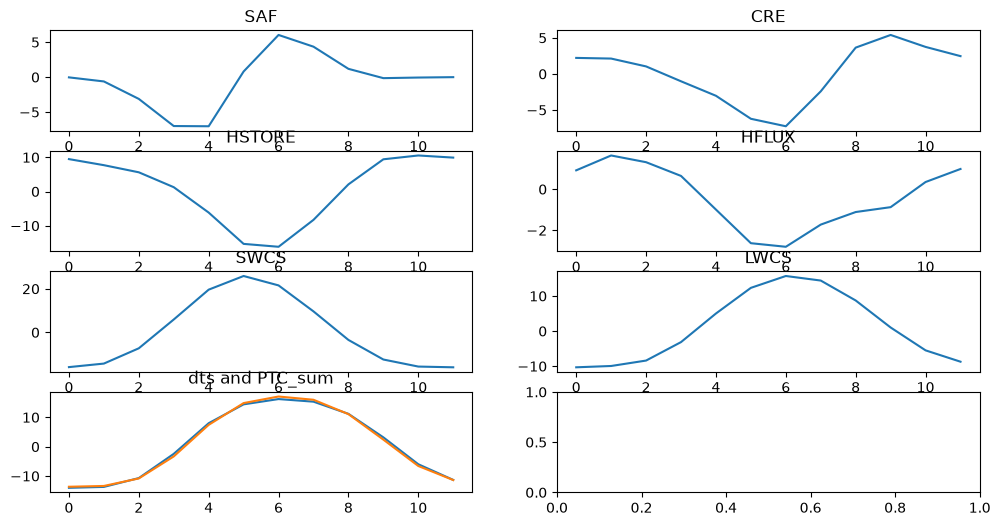

In [25]:

period = "historical"
ds, base = read_data(period=period)

base_mean = base.mean(dim="time")#.sel(time=base.time.dt.month.isin([6, 7, 8])).mean(dim="time")#.groupby('time.month').mean() 
ds_mean = ds#.sel(time=base.time.dt.month.isin([6, 7, 8]))#.groupby('time.month').mean() 
month = np.arange(1,13)

print("test 1")
ptc_temp = fhb.partial_temperature_contributions(ds_mean,base_mean).sel(lat=slice(66,None)).load()

print("test2 ")


areacella = xr.open_dataset("/projects/NS9034K/CMIP6/CMIP/NCC/NorESM2-MM/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_NorESM2-MM_piControl_r1i1p1f1_gn.nc")
area = areacella.areacella.sel(lat=slice(66,None))/areacella.areacella.sel(lat=slice(66,None)).sum(dim=("lat","lon"))

#Selecting the Arctic region
ptc_subset = ptc_temp.groupby('time.month').mean()#.sel(month=[1,2,10,11,12])
ptc_ave = (ptc_subset*area).sum(dim=("lat","lon"))


fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_ave.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_ave.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_ave.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_ave.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_ave.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_ave.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_ave.dts[:12].values, label="dts")
ax[3,0].plot(ptc_ave.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

In [23]:
ds.groupby('time.month').mean(dim="time")

<xarray.Dataset> Size: 29MB
Dimensions:    (month: 12, bnds: 2, lat: 192, lon: 288)
Coordinates:
  * month      (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon        (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: bnds
Data variables: (12/14)
    time_bnds  (month, bnds) object 192B dask.array<chunksize=(1, 2), meta=np.ndarray>
    lat_bnds   (month, lat, bnds) float64 37kB dask.array<chunksize=(1, 192, 2), meta=np.ndarray>
    lon_bnds   (month, lon, bnds) float64 55kB dask.array<chunksize=(1, 288, 2), meta=np.ndarray>
    hfss       (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    hfls       (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    rsuscs     (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    ...         ...
    rlus       (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    rsds       (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    ts         (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    rldscs     (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    rlns       (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
    rlnscs     (month, lat, lon) float32 3MB dask.array<chunksize=(1, 192, 288), meta=np.ndarray>
Attributes: (12/49)
    Conventions:               CF-1.7 CMIP-6.2
    activity_id:               ScenarioMIP
    branch_method:             Hybrid-restart from year 2015-01-01 of historical
    branch_time:               0.0
    branch_time_in_child:      0.0
    branch_time_in_parent:     60225.0
    ...                        ...
    title:                     NorESM2-MM output prepared for CMIP6
    variable_id:               hfss
    variant_label:             r1i1p1f1
    license:                   CMIP6 model data produced by NCC is licensed u...
    cmor_version:              3.6.0
    tracking_id:               hdl:21.14100/07f77a64-8ff9-4624-9a35-5b7f10868d98